# 01 · Recopilación y transformación de datos (ETL)

**Proyecto integrador – Equipo 4** · Responsable: **Víctor Manuel David Rodríguez**

**Problema de negocio.** Una tienda en línea del Reino Unido vende artículos de regalo y decoración, sobre todo a mayoristas. Necesita saber **qué vende, a quién, cuándo y dónde**, y **cuántas unidades de cada producto venderá la próxima semana** para reponer inventario sin quedarse corta ni sobrestockear.

Este notebook cubre la **fase 1 de la guía**: identificar las fuentes, extraerlas, transformarlas con reglas de negocio explícitas, validar su calidad y cargarlas listas para el EDA, el modelo predictivo y Power BI.

| # | Fuente | Formato | Qué aporta |
|---|--------|---------|------------|
| 1 | Online Retail II – UCI (id 502), copia idéntica en OpenML (id 43368) | Parquet (tabular) | 1.067.371 líneas de factura, dic-2009 a dic-2011 |
| 2 | API Nager.Date – festivos del Reino Unido | JSON (semiestructurado) | Festivos oficiales para el calendario |
| 3 | API del Banco Mundial – catálogo de países | JSON (semiestructurado) | Región y nivel de ingreso de cada país |

El código vive en `src/etl.py`; aquí se ejecuta paso a paso y se explica cada decisión. Las reglas están documentadas en `docs/reglas_de_negocio.md`.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
from src import config, etl

## 1. Extracción

### 1.1 Transacciones de la tienda (fuente 1)
La función `extraer_ventas()` descarga el archivo una sola vez a `data/raw/` y verifica que lleguen las 1.067.371 filas que reporta UCI.

In [2]:
crudo = etl.extraer_ventas()
print(f"Filas: {len(crudo):,} | Columnas: {crudo.shape[1]}")
crudo.head()

Filas: 1,067,371 | Columnas: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


**Diccionario de datos original** (según UCI):

In [3]:
diccionario = pd.DataFrame({
    "columna": ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"],
    "significado": ["Número de factura (6 dígitos; si empieza por 'C' es una anulación)",
                    "Código del producto (5 dígitos + letra opcional)", "Nombre del producto",
                    "Unidades por línea", "Fecha y hora de la factura", "Precio unitario en libras (GBP)",
                    "Identificador del cliente", "País del cliente"],
    "tipo": crudo.dtypes.astype(str).values,
    "nulos": crudo.isna().sum().values,
    "% nulos": (crudo.isna().mean() * 100).round(2).values,
})
diccionario

,columna,significado,tipo,nulos,% nulos
0,Invoice,Número de factura (6 dígitos; si empieza por '...,str,0,0.00
1,StockCode,Código del producto (5 dígitos + letra opcional),str,0,0.00
2,Description,Nombre del producto,str,4474,0.42
3,Quantity,Unidades por línea,int64,0,0.00
4,InvoiceDate,Fecha y hora de la factura,str,0,0.00
5,Price,Precio unitario en libras (GBP),float64,0,0.00
6,Customer ID,Identificador del cliente,float64,243007,22.77
7,Country,País del cliente,str,0,0.00


### 1.2 Problemas de calidad detectados en los datos crudos
Antes de definir reglas hay que medir los problemas:

In [4]:
c = crudo.copy()
codigo = c["StockCode"].astype(str).str.strip().str.upper()
problemas = pd.DataFrame({
    "problema": ["Filas duplicadas exactas", "Facturas de anulación (empiezan por C)",
                 "Ajustes contables (facturas A)", "Códigos que no son producto (POST, M, D...)",
                 "Precio menor o igual a 0", "Cantidad negativa sin ser anulación",
                 "Clientes sin identificar", "Productos sin descripción",
                 "Líneas con |cantidad| >= 10.000"],
    "filas": [c.duplicated().sum(), c["Invoice"].str.startswith("C").sum(),
              c["Invoice"].str.startswith("A").sum(), (~codigo.str.match(etl.PATRON_PRODUCTO)).sum(),
              (c["Price"] <= 0).sum(), ((c["Quantity"] < 0) & ~c["Invoice"].str.startswith("C")).sum(),
              c["Customer ID"].isna().sum(), c["Description"].isna().sum(),
              (c["Quantity"].abs() >= etl.UMBRAL_CANTIDAD_ATIPICA).sum()],
})
problemas["% del total"] = (problemas["filas"] / len(c) * 100).round(2)
problemas

,problema,filas,% del total
0,Filas duplicadas exactas,34335,3.22
1,Facturas de anulación (empiezan por C),19494,1.83
2,Ajustes contables (facturas A),6,0.00
3,"Códigos que no son producto (POST, M, D...)",5932,0.56
4,Precio menor o igual a 0,6207,0.58
5,Cantidad negativa sin ser anulación,3457,0.32
6,Clientes sin identificar,243007,22.77
7,Productos sin descripción,4474,0.42
8,Líneas con |cantidad| >= 10.000,15,0.00


Códigos que **no** son productos (cargos, portes, descuentos, comisiones). Se excluyen del análisis de productos (regla R3):

In [5]:
no_producto = c[~codigo.str.match(etl.PATRON_PRODUCTO)]
(no_producto.groupby(codigo[~codigo.str.match(etl.PATRON_PRODUCTO)])
 .agg(lineas=("Quantity", "size"), ejemplo=("Description", "first"))
 .sort_values("lineas", ascending=False).head(12))

,lineas,ejemplo
StockCode,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1426,Manual
C2,282,CARRIAGE
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE


Las cantidades extremas corresponden a pedidos masivos; los dos mayores se **anularon a los pocos minutos** (regla R8):

In [6]:
c.loc[c["Quantity"].abs() >= etl.UMBRAL_CANTIDAD_ATIPICA,
      ["Invoice", "StockCode", "Description", "Quantity", "Price", "InvoiceDate"]]

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,2010-02-15 11:57:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,2010-03-17 13:09:00
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,2010-03-17 13:09:00
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,2010-03-17 13:09:00
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2010-03-23 15:36:00
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2010-03-23 15:36:00
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2010-03-23 15:36:00
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,2010-03-23 15:36:00
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,0.00,2010-05-10 14:55:00


### 1.3 Festivos del Reino Unido (fuente 2) y países del Banco Mundial (fuente 3)
Las dos APIs devuelven JSON. Se guarda una copia en `data/external/` para que el proceso sea **reproducible** aunque la API cambie o no esté disponible.

In [7]:
festivos_crudo = etl.extraer_festivos()
print("Festivos recibidos:", len(festivos_crudo))
festivos_crudo[["date", "localName", "global", "counties"]].head(8)

Festivos recibidos: 39


,date,localName,global,counties
0,2009-01-01,New Year's Day,False,"[GB-ENG, GB-NIR, GB-SCT, GB-WLS]"
1,2009-01-02,2 January,False,[GB-SCT]
2,2009-03-17,Saint Patrick's Day,False,[GB-NIR]
3,2009-04-10,Good Friday,True,None
4,2009-04-13,Easter Monday,False,"[GB-ENG, GB-WLS, GB-NIR]"
5,2009-05-04,Early May Bank Holiday,True,None
6,2009-05-25,Spring Bank Holiday,True,None
7,2009-07-13,Battle of the Boyne,False,[GB-NIR]


In [8]:
paises_crudo = etl.extraer_paises()
print("Registros del Banco Mundial:", len(paises_crudo))
paises_crudo[["id", "iso2Code", "name", "region.value", "incomeLevel.value"]].head()

Registros del Banco Mundial: 296


,id,iso2Code,name,region.value,incomeLevel.value
0,ABW,AW,Aruba,Latin America & Caribbean,High income
1,AFE,ZH,Africa Eastern and Southern,Aggregates,Aggregates
2,AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income
3,AFR,A9,Africa,Aggregates,Aggregates
4,AFW,ZI,Africa Western and Central,Aggregates,Aggregates


## 2. Transformación

Se aplican las reglas de negocio en este orden (detalle en `docs/reglas_de_negocio.md`):

| Regla | Qué hace | Por qué |
|---|---|---|
| R9 | Una sola descripción por producto (la más frecuente) | El mismo código aparece escrito de varias formas |
| R5 | Elimina duplicados exactos | Son registros repetidos del sistema, inflan las ventas |
| R2 | Marca devoluciones (factura C) y excluye ajustes contables (factura A) | Las devoluciones sirven para la tasa de devolución; los ajustes no son ventas |
| R3 | Deja solo códigos de producto | Portes, comisiones y descuentos no son demanda de productos |
| R1 | Precio > 0 y signo de cantidad coherente con el tipo | Líneas con precio 0 son ajustes de inventario sin valor comercial |
| R8 | Excluye líneas con \|cantidad\| ≥ 10.000 | Pedidos masivos anulados que distorsionan promedios |
| R6 | Clientes sin ID → "SIN REGISTRO" | Se conservan para totales de ventas, no para análisis de clientes |
| R7 | Normaliza el país (EIRE → Irlanda, RSA → Sudáfrica…) y lo enriquece con región y nivel de ingreso | Integración con la fuente 3 |
| R4 | Importe = cantidad × precio (GBP) | Medida principal de ventas |
| R10 | Atributos de calendario y festivos | Integración con la fuente 2 |

In [9]:
festivos = etl.transformar_festivos(festivos_crudo)
paises = etl.transformar_paises(paises_crudo)
ventas, bitacora = etl.transformar_ventas(crudo, paises, festivos)
bitacora

,regla,descripcion,filas_antes,filas_despues,filas_eliminadas
0,R0,Filas extraídas del dataset original,1067371,1067371,0
1,R5,Duplicados exactos eliminados,1067371,1033034,34337
2,R2,Ajustes contables (facturas A) excluidos,1033034,1033028,6
3,R3,"Cargos y ajustes no producto excluidos (POST, ...",1033028,1027214,5814
4,R1,Líneas con precio 0 o cantidad incoherente exc...,1027214,1021252,5962
5,R8,"Líneas con |cantidad| >= 10,000 excluidas",1021252,1021239,13
6,FIN,Filas en la tabla limpia,1021239,1021239,0


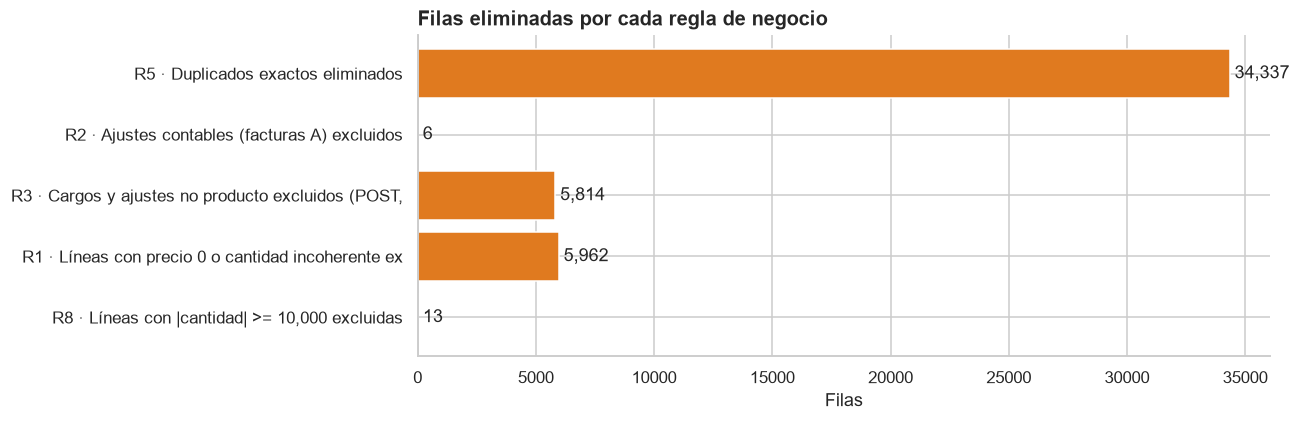

Se conserva el 95.7% de las filas originales.


In [10]:
import matplotlib.pyplot as plt
from src import visualizacion as viz
viz.aplicar_estilo()
pasos = bitacora[bitacora["filas_eliminadas"] > 0]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(pasos["regla"] + " · " + pasos["descripcion"].str.slice(0, 45), pasos["filas_eliminadas"], color=viz.NARANJA)
ax.invert_yaxis()
for i, v in enumerate(pasos["filas_eliminadas"]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Filas eliminadas por cada regla de negocio")
ax.set_xlabel("Filas")
viz.guardar(fig, "etl_filas_eliminadas_por_regla")
plt.show()
retenido = bitacora.iloc[-1]["filas_despues"] / bitacora.iloc[0]["filas_antes"]
print(f"Se conserva el {retenido:.1%} de las filas originales.")

### Normalización de países: antes y después

In [11]:
(ventas.groupby(["pais_origen", "pais", "region", "nivel_ingreso"]).size()
 .rename("lineas").reset_index().sort_values("lineas", ascending=False).head(12))

,pais_origen,pais,region,nivel_ingreso,lineas
40,United Kingdom,United Kingdom,Europa y Asia Central,Ingreso alto,938859
11,EIRE,Ireland,Europa y Asia Central,Ingreso alto,17382
15,Germany,Germany,Europa y Asia Central,Ingreso alto,16654
14,France,France,Europa y Asia Central,Ingreso alto,13523
26,Netherlands,Netherlands,Europa y Asia Central,Ingreso alto,5016
34,Spain,Spain,Europa y Asia Central,Ingreso alto,3641
36,Switzerland,Switzerland,Europa y Asia Central,Ingreso alto,3116
3,Belgium,Belgium,Europa y Asia Central,Ingreso alto,2960
30,Portugal,Portugal,Europa y Asia Central,Ingreso alto,2459
0,Australia,Australia,Asia Oriental y Pacífico,Ingreso alto,1878


## 3. Validación de calidad
Pruebas automáticas sobre la tabla limpia. Si alguna falla, `ejecutar_etl()` se detiene para no cargar datos malos.

In [12]:
calidad = etl.validar_calidad(ventas)
calidad

,prueba,resultado
0,Sin nulos en columnas clave,OK
1,Precio unitario siempre > 0,OK
2,Ventas con importe positivo,OK
3,Devoluciones con importe negativo,OK
4,Sin duplicados exactos,OK
5,Todos los países tienen región,OK
6,Fechas dentro de dic-2009 a dic-2011,OK
7,Una descripción por producto,OK


## 4. Carga
La tabla limpia se guarda en Parquet (rápido y conserva tipos) y los catálogos en CSV dentro de `data/processed/`.

In [13]:
config.PROCESSED.mkdir(parents=True, exist_ok=True)
ventas.to_parquet(config.VENTAS_LIMPIAS, index=False)
festivos.to_csv(config.FESTIVOS_LIMPIOS, index=False)
paises.to_csv(config.PAISES_LIMPIOS, index=False)
bitacora.to_csv(config.REPORTE_CALIDAD, index=False)
for ruta in [config.VENTAS_LIMPIAS, config.FESTIVOS_LIMPIOS, config.PAISES_LIMPIOS, config.REPORTE_CALIDAD]:
    print(f"{ruta.relative_to(config.RAIZ)}  ({ruta.stat().st_size/1e6:.2f} MB)")

data\processed\ventas_limpias.parquet  (8.56 MB)
data\processed\festivos.csv  (0.00 MB)
data\processed\paises.csv  (0.02 MB)
data\processed\reporte_calidad.csv  (0.00 MB)


### Estructura final de la tabla limpia

In [14]:
ventas.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1021239 entries, 0 to 1021238
Data columns (total 22 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   factura             1021239 non-null  str           
 1   tipo_transaccion    1021239 non-null  str           
 2   fecha_hora          1021239 non-null  datetime64[us]
 3   fecha               1021239 non-null  datetime64[us]
 4   anio                1021239 non-null  int32         
 5   mes                 1021239 non-null  int32         
 6   dia_semana          1021239 non-null  int32         
 7   hora                1021239 non-null  int32         
 8   semana_inicio       1021239 non-null  datetime64[us]
 9   es_festivo          1021239 non-null  bool          
 10  codigo_producto     1021239 non-null  str           
 11  descripcion         1021239 non-null  string        
 12  cantidad            1021239 non-null  int64         
 13  precio_unitario     102

In [15]:
resumen = pd.Series({
    "Periodo": f"{ventas['fecha'].min():%d-%m-%Y} a {ventas['fecha'].max():%d-%m-%Y}",
    "Líneas de factura": f"{len(ventas):,}",
    "Facturas de venta": f"{ventas.loc[ventas.tipo_transaccion=='Venta','factura'].nunique():,}",
    "Facturas de devolución": f"{ventas.loc[ventas.tipo_transaccion=='Devolución','factura'].nunique():,}",
    "Productos": f"{ventas['codigo_producto'].nunique():,}",
    "Clientes identificados": f"{ventas.loc[ventas.cliente_registrado,'cliente_id'].nunique():,}",
    "Países": f"{ventas['pais'].nunique()}",
    "Ventas netas (GBP)": f"£{ventas['importe'].sum():,.0f}",
    "Días festivos en el periodo": f"{ventas.loc[ventas.es_festivo,'fecha'].nunique()} con ventas",
})
resumen.to_frame("valor")

,valor
Periodo,01-12-2009 a 09-12-2011
Líneas de factura,"1,021,239"
Facturas de venta,"39,513"
Facturas de devolución,"7,403"
Productos,"4,737"
Clientes identificados,"5,875"
Países,43
Ventas netas (GBP),"£18,909,854"
Días festivos en el periodo,0 con ventas


## 5. Conclusiones del ETL
- Se integraron **tres fuentes** (un archivo tabular y dos APIs JSON) en una sola tabla limpia con columnas en español.
- Las reglas eliminan sobre todo **duplicados** y **líneas sin valor comercial**; la tabla final conserva cerca del 96 % de las filas originales, así que el análisis no pierde representatividad.
- Las **devoluciones se conservan** marcadas (importe negativo) para medir la tasa de devolución en el dashboard.
- Los clientes sin ID (~22 % de las líneas) se conservan para los totales de ventas, pero se excluyen del análisis de clientes.
- Todas las **pruebas de calidad quedaron en OK**.

**Siguiente paso:** el EDA (`02_eda.ipynb`), el modelo predictivo (`04_modelo_predictivo.ipynb`) y el modelo de datos para Power BI (`03_modelo_datos_bi.ipynb`) parten de `data/processed/ventas_limpias.parquet`.

> Para regenerar todo desde la terminal: `python -m src.etl`